# Acupuncture utilization: conditions or evidence-group counts

Choose one of two ridge logistic models: individual condition predictors, or
counts of distinct conditions within each supplied evidence group. Both adjust
for age bucket, gender, recorded race and RUCC. The reporting references remain
**age <35** and **RUCC 6**.

A patient can have conditions in several groups. Evidence groups are condition
metadata supplied by you; this notebook does not assign or validate clinical
benefit labels. The outcome is observed acupuncture use, not treatment benefit.

This notebook is self-contained. Start with the fictional synthetic example, then
set USE_SYNTHETIC_DEMO to False and edit the configuration. Restart the kernel and
run all cells after changing modes. The original notebooks are preserved.

## 1. Dependencies

Use Python 3.10 or later. If needed, uncomment and run the installation line below,
then restart the kernel. All model/data processing occurs locally.

In [ ]:
# Uncomment only if these packages are missing in your notebook environment:
# %pip install "numpy>=1.24,<3" "pandas>=2,<4" "scikit-learn>=1.3,<2" "joblib>=1.3,<2" matplotlib

In [1]:
from __future__ import annotations
import json
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)
import matplotlib.pyplot as plt
from IPython.display import display


import pyodbc
import urllib
from sqlalchemy import create_engine

warnings.filterwarnings('error', category=ConvergenceWarning)
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.9.1


## 2. Configuration

Set MODEL_MODE to **"conditions"** to retain individual condition effects, or
**"evidence_groups"** to replace them with six group counts. These predictors are
kept in separate models because group counts are sums of condition indicators.

Add an **evidence_group** column to your long table. Every condition must have
exactly one nonmissing label across its records. Alternatively, supply a
two-column condition/evidence_group CSV using EVIDENCE_LOOKUP_CSV. Conflicting
assignments or unrecognized labels stop the run. No clinical label is inferred.

Missing labels are audited as Unmapped, with a separate burden predictor in group
mode. REQUIRE_COMPLETE_EVIDENCE_MAPPING = True instead stops if any are missing.
A group model needs at least one mapped condition. Patients with no conditions
remain in the denominator when supplied through a complete roster.

USE_COUNTS adds diagnosis-frequency predictors in **condition mode only**.
It does not control distinct-condition group counts, which are always computed
from presence. Use DUPLICATE_COUNTS = "max" for repeated cumulative totals, or
"sum" only for disjoint records; either choice still counts a distinct condition
once per patient in group mode. The default "error" makes duplicate rows explicit.

Age buckets: <35, 35-44, 45-54, 55-64, 65-74, 75+. Missing age/RUCC are retained
as Unknown. Edit COLUMN_MAP for source column names. Rurality must be RUCC 1-9.
Outputs have separate folders for each mode so rerunning the other mode preserves
the first model's results.

# Import the data

In [2]:
%%time
# establish the connection parameters
odbc_str = ("DRIVER={ODBC Driver 18 for SQL Server};"
            "SERVER=VHACDWA01.vha.med.va.gov,1433;"
            "DATABASE=OPCCCT_CIH;"
            "Trusted_Connection=yes;"
            "Encrypt=yes;"
            "TrustServerCertificate=no;")

# connect
params = urllib.parse.quote_plus(odbc_str)
engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")

# read in the data
df = pd.read_sql("SELECT * FROM [OPCCCT_CIH].[dflt].[logit_patient_data]", engine)
df = df.loc[df['gender'].notnull()]
df['evidence_group'] = np.where(df['condition']=='Diabetes','Group B', df['evidence_group'])

CPU times: total: 3min 29s
Wall time: 7min 37s


In [25]:
USE_SYNTHETIC_DEMO = False
EVIDENCE_LOOKUP_CSV = None  # Or Path(r"C:\path\condition_evidence_lookup.csv")
MODEL_MODE = "evidence_groups"  # "conditions" or "evidence_groups"
REQUIRE_COMPLETE_EVIDENCE_MAPPING = False

COLUMN_MAP = {
    "patientICN": "PatientICN",
    "condition": "Condition",
    "times_diagnosed": "diagnosis_count",
    "race": "race_mod",
    "evidence_group": "evidence_group",
    "rurality": "rurality",
}
EVIDENCE_GROUPS = [
    "Group A - High/Strong",
    "Group A - Moderate",
    "Group A - Low/Very Low",
    "Group B",
    "Group C",
    "Group D",
]
UNMAPPED_GROUP = "Unmapped"
EVIDENCE_FEATURES = {
    group: f"egcount__{i + 1}" for i, group in enumerate(EVIDENCE_GROUPS)
}
EVIDENCE_FEATURES[UNMAPPED_GROUP] = "egcount__unmapped"

AGE_LABELS = ["<35", "35-44", "45-54", "55-64", "65-74", "75+"]
AGE_REFERENCE = "<35"
RURALITY_REFERENCE = "6"
GENDER_REFERENCE = "Male"
RACE_REFERENCE = "WHITE"
USE_COUNTS = False  # Diagnosis frequency; allowed only when MODEL_MODE == "conditions".
DUPLICATE_COUNTS = "sum"  # "error", "max", "sum"
OUTER_FOLDS = 5
RANDOM_SEED = 42
JOBS = 1

if MODEL_MODE not in {"conditions", "evidence_groups"}:
    raise ValueError('MODEL_MODE must be "conditions" or "evidence_groups".')
if MODEL_MODE == "evidence_groups" and USE_COUNTS:
    raise ValueError("USE_COUNTS is diagnosis frequency: set it False in evidence-group mode.")
if DUPLICATE_COUNTS not in {"error", "max", "sum"}:
    raise ValueError("DUPLICATE_COUNTS must be error, max or sum.")
try:
    rucc_reference_number = float(RURALITY_REFERENCE)
except (TypeError, ValueError):
    raise ValueError("RURALITY_REFERENCE must be RUCC 1-9.") from None
if rucc_reference_number not in range(1, 10):
    raise ValueError("RURALITY_REFERENCE must be RUCC 1-9.")
RURALITY_REFERENCE = str(int(rucc_reference_number))
if AGE_REFERENCE not in AGE_LABELS:
    raise ValueError("AGE_REFERENCE must match an age bucket label.")

OUTPUT_BASE = Path.cwd() / "acupuncture_evidence_outputs"
run_name = "synthetic_demo" if USE_SYNTHETIC_DEMO else "patient_analysis"
run_name += "_" + MODEL_MODE
if MODEL_MODE == "conditions":
    run_name += "_counts" if USE_COUNTS else "_presence"
OUTPUT_DIR = OUTPUT_BASE / run_name
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Data:", "FICTIONAL SYNTHETIC DEMO" if USE_SYNTHETIC_DEMO else "YOUR INPUT DATA")
print("Predictor mode:", MODEL_MODE)
print("Age reference:", AGE_REFERENCE, "; RUCC reference:", RURALITY_REFERENCE)
print("Output folder:", OUTPUT_DIR.resolve())

Data: YOUR INPUT DATA
Predictor mode: evidence_groups
Age reference: <35 ; RUCC reference: 6
Output folder: C:\Users\VACOGRAUPE\OneDrive - Department of Veterans Affairs\Desktop\acupuncture_python_code\acupuncture_evidence_outputs\patient_analysis_evidence_groups


## 3. Input checks and patient-level transformation

The long table has patient ID, age, gender, race, rurality, condition and the
binary training outcome current_acupuncture_user. Evidence_group is attached to
the condition, not a patient-level demographic. Diagnosis_count is optional when
USE_COUNTS is False. Source names PatientICN, Condition, race_mod, RUCC and
diagnosis_count are recognized, as are the earlier canonical names.

Example: a patient with two distinct High/Strong conditions and one Group B
condition receives counts 2 and 1, even if those diagnoses appear 30 times.
A patient with no condition in a group receives 0. These are counts within your
supplied condition catalog and observation window, not all possible diseases.


In [26]:
ID = "PatientICN"
OUTCOME = "current_acupuncture_user"
PERSON_FIELDS = ["age", "gender", "race_mod", "rurality", OUTCOME]

def add_age_buckets(wide: pd.DataFrame) -> pd.DataFrame:
    values = pd.to_numeric(wide["age"], errors="raise").astype(float)
    if (not np.isfinite(values.dropna()).all()) or values.dropna().lt(0).any():
        raise ValueError("Age must be nonnegative and finite, or missing.")
    wide["age_bucket"] = pd.cut(
        values, bins=[-np.inf, 35, 45, 55, 65, 75, np.inf],
        labels=AGE_LABELS, right=False,
    ).astype(object).fillna("Unknown")
    wide["rurality"] = wide["rurality"].fillna("Unknown").astype(str)
    wide["gender"] = wide["gender"].replace("__MISSING__", "Unknown").fillna("Unknown")
    wide["race_mod"] = wide["race_mod"].replace("__MISSING__", "UNKNOWN").fillna("UNKNOWN")
    return wide

def long_to_wide(
    long: pd.DataFrame,
    *,
    duplicate_counts: str = "error",
) -> tuple[pd.DataFrame, list[str]]:
    """
    Duplicate patient-condition counts require an explicit aggregation rule.
    Missing counts for a recorded condition remain missing, not zero.
    """
    tables = [long.reindex(columns=[ID] + PERSON_FIELDS)]
    info = pd.concat(tables, ignore_index=True).drop_duplicates()
    info = info.loc[~info.index.duplicated(keep='first')]
    info['count'] = info.groupby([ID])[ID].transform('count')
    info['unknown_count'] = np.where(info['race_mod']=='UNKNOWN', 1,0)
    info['count_unknown'] = info.groupby([ID])['unknown_count'].transform('sum')
    info['remove'] = np.where((info['count']>=2) & (info['count_unknown']<info['count']) & (info['race_mod']=='UNKNOWN'), 1, 0)
    info = info.loc[(info['remove']==0)]
    info = info.drop_duplicates(subset=[ID],keep="first")
    group = info.groupby(ID, sort=False)
    conflicts = group[PERSON_FIELDS].nunique(dropna=True).gt(1).sum()
    if conflicts.any():
        details = {k: int(v) for k, v in conflicts.items() if v}
        raise ValueError(
            f"Conflicting patient-level values (counts by field): {details}. "
            "Resolve these at a common index date; do not arbitrarily take first."
        )
    # first() selects the first nonmissing value only after consistency checks.
    people = group[PERSON_FIELDS].first()
    people.index.name = ID
    for col in ["gender", "race_mod"]:
        people[col] = people[col].fillna("__MISSING__").astype(str)

    dx = long.loc[long["condition"].notna(), [ID, "condition", "times_diagnosed"]].copy()
    known_counts = dx["times_diagnosed"].dropna()
    if known_counts.lt(1).any() or not np.equal(known_counts, np.floor(known_counts)).all():
        raise ValueError("A recorded condition needs a positive integer count or missing.")
    keys = [ID, "condition"]
    if dx.duplicated(keys).any():
        if duplicate_counts == "error":
            raise ValueError(
                "Repeated patient-condition pairs. Use --duplicate-counts max "
                "for repeated cumulative totals or sum for disjoint counts."
            )
        if duplicate_counts == "sum" and dx["times_diagnosed"].isna().any():
            raise ValueError("Cannot sum counts with missing components.")
        dx = dx.groupby(keys, as_index=False)["times_diagnosed"].agg(duplicate_counts)

    conditions = sorted(dx["condition"].unique().tolist())
    if conditions:
        presence = (
            dx.assign(present=1)
            .pivot(index=ID, columns="condition", values="present")
            .reindex(index=people.index, columns=conditions)
            .fillna(0)
            .astype("int8")
        )
        counts = (
            dx.pivot(index=ID, columns="condition", values="times_diagnosed")
            .reindex(index=people.index, columns=conditions)
            .where(presence.eq(1), 0.0)
        )
        people = people.join(presence.add_prefix("dx__")).join(counts.add_prefix("count__"))
    return people.reset_index(), conditions

def normalize_evidence(value):
    if pd.isna(value) or not str(value).strip():
        return pd.NA
    text = " ".join(str(value).replace("\u2013", "-").replace("\u2014", "-").split())
    missing = {"nan", "none", "<na>", "unknown", "unmapped", "__missing__"}
    if text.casefold() in missing:
        return pd.NA
    canonical = {label.casefold(): label for label in EVIDENCE_GROUPS}
    if text.casefold() not in canonical:
        raise ValueError(f"Unknown evidence group {value!r}; use one of EVIDENCE_GROUPS.")
    return canonical[text.casefold()]


def condition_mapping(long, conditions, lookup_path=None, *, require_complete=False):
    """Validate one label per condition; missing rows inherit a known assignment."""
    frames = []
    if "evidence_group" in long:
        frames.append(long.reindex(columns=["condition", "evidence_group"]).copy())
    if lookup_path is not None:
        lookup = pd.read_csv(lookup_path, dtype="string", keep_default_na=False)
        lookup.columns = lookup.columns.str.strip()
        if lookup.columns.duplicated().any():
            raise ValueError("Duplicate evidence-lookup column names.")
        renamed = {}
        for canonical, aliases in {
            "condition": ["condition", "Condition"],
            "evidence_group": ["evidence_group", "EvidenceGroup", "Evidence Group", "Evidence_Group"],
        }.items():
            choices = [COLUMN_MAP.get(canonical), canonical] + aliases
            match = next((name for name in choices if name and name in lookup), None)
            if match is None:
                raise ValueError(f"Lookup needs a {canonical} column.")
            renamed[canonical] = lookup[match]
        frames.append(pd.DataFrame(renamed))
    data = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(
        columns=["condition", "evidence_group"]
    )
    data["condition"] = data["condition"].astype("string").str.strip().replace("", pd.NA)
    data["evidence_group"] = data["evidence_group"].map(normalize_evidence)
    if (data["condition"].isna() & data["evidence_group"].notna()).any():
        raise ValueError("An evidence label needs a condition name.")
    valid = data.dropna(subset=["condition", "evidence_group"]).drop_duplicates()
    conflicts = valid.groupby("condition")["evidence_group"].nunique()
    conflicts = conflicts[conflicts.gt(1)].index.tolist()
    if conflicts:
        raise ValueError(f"Multiple evidence groups for condition(s): {conflicts[:10]}")
    known = valid.set_index("condition")["evidence_group"].to_dict()
    mapping = {c: known.get(c, UNMAPPED_GROUP) for c in conditions}
    missing = [c for c, group in mapping.items() if group == UNMAPPED_GROUP]
    if require_complete and missing:
        raise ValueError(f"Evidence labels missing for {len(missing)} condition(s): {missing[:10]}")
    return mapping


def evidence_columns(mapping):
    groups = EVIDENCE_GROUPS + ([UNMAPPED_GROUP] if UNMAPPED_GROUP in mapping.values() else [])
    return [EVIDENCE_FEATURES[group] for group in groups]


def add_evidence_counts(wide, conditions, mapping):
    """Sum presence flags, never frequency counts; training catalog fixes scoring."""
    for group, feature in EVIDENCE_FEATURES.items():
        members = [f"dx__{c}" for c in conditions if mapping[c] == group]
        # int32 avoids overflowing int8 when patients have many conditions.
        wide[feature] = wide[members].sum(axis=1).astype("int32") if members else 0
    return wide

## 4. Model and interpretation helpers

Both modes use ridge logistic regression and the same nested validation process.
In condition mode, a diagnosis indicator compares having a record of that
condition with having no record, adjusting for demographics and other conditions.

In evidence-group mode, the six **distinct condition counts** enter together as
numeric predictors. Exp(coefficient) is the adjusted odds ratio for **one
additional condition in that group**, holding the other group counts and
demographics fixed. This assumes a constant effect on log odds per additional
condition and a common effect for conditions within the same group. The groups
have no numerical ranking, and there is **no single reference evidence group**.

For example, an OR of 1.20 means 20% higher odds per additional condition; two
additional conditions multiply odds by 1.20 squared. It does not mean 20 percentage
points higher probability, that a condition caused use, or that treatment works.

All demographic categories are retained for ridge fitting. Reports compare
exp(beta_category - beta_reference), so age <35 and RUCC 6 have reference OR 1.
A group with no variation is marked Not estimated rather than treated as a null
effect. No confidence intervals or p-values are estimated.

In [27]:
def make_pipeline(conditions: list[str], use_counts: bool) -> Pipeline:
    parts = [
        ("age_group", OneHotEncoder(handle_unknown="ignore"), ["age_bucket"]),
        ("demographics", OneHotEncoder(handle_unknown="ignore"), ["gender", "race_mod", "rurality"]),
    ]
    if MODEL_MODE == "evidence_groups":
        parts.append(("evidence_counts", "passthrough", evidence_columns(evidence_mapping)))
    elif conditions:
        parts.append(("diagnosis_presence", "passthrough", [f"dx__{c}" for c in conditions]))
        if use_counts:
            counts = Pipeline([
                ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
                ("scale", StandardScaler(with_mean=False)),
            ])
            parts.append(("diagnosis_counts", counts, [f"count__{c}" for c in conditions]))
    return Pipeline([
        ("prepare", ColumnTransformer(parts, remainder="drop")),
        ("logit", LogisticRegression(solver="lbfgs", max_iter=3000, class_weight=None)),
    ])


def fit_search(pipeline, X, y, seed, jobs):
    folds = min(3, int(y.value_counts().min()))
    if folds < 2:
        raise ValueError("Not enough users/nonusers for inner cross-validation.")
    search = GridSearchCV(
        clone(pipeline), {"logit__C": [0.01, 0.1, 1.0, 10.0]},
        scoring="neg_log_loss",
        cv=StratifiedKFold(folds, shuffle=True, random_state=seed),
        n_jobs=jobs, error_score="raise", refit=True,
    )
    search.fit(X, y)
    return search


def make_comparison_table(model, wide, y):
    names = model.named_steps["prepare"].get_feature_names_out()
    coefficients = dict(zip(names, model.named_steps["logit"].coef_[0]))
    groups = [
        ("Age", "age_bucket", "age_group__age_bucket_", AGE_REFERENCE, AGE_LABELS + ["Unknown"]),
        ("RUCC", "rurality", "demographics__rurality_", RURALITY_REFERENCE,
         [str(i) for i in range(1, 10)] + ["Unknown"]),
        ("Gender", "gender", "demographics__gender_", GENDER_REFERENCE, sorted(wide["gender"].unique())),
        ("Race/ethnicity", "race_mod", "demographics__race_", RACE_REFERENCE, sorted(wide["race_mod"].unique())),
    ]
    records = []
    for group, column, prefix, reference, categories in groups:
        ref_key = prefix + reference
        for category in categories:
            key = prefix + category
            mask = wide[column].eq(category)
            estimated = key in coefficients and ref_key in coefficients
            delta = float(coefficients[key] - coefficients[ref_key]) if estimated else np.nan
            odds_ratio = float(np.exp(delta)) if estimated else np.nan
            records.append({
                "comparison_group": group, "category": category, "reference": reference,
                "comparison_log_odds": delta, "adjusted_odds_ratio": odds_ratio,
                "odds_difference_percent": 100 * (odds_ratio - 1),
                "patients": int(mask.sum()), "observed_users": int(y.loc[mask].sum()),
                "status": ("Reference" if category == reference else "Estimated") if estimated
                          else "Not estimated: category or reference absent",
            })
    return pd.DataFrame(records)

def probability_metrics(y: pd.Series, p: np.ndarray) -> dict:
    return {
        "patients": int(len(y)),
        "observed_users": int(y.sum()),
        "sum_predicted_probabilities": float(p.sum()),
        "observed_use_rate": float(y.mean()),
        "mean_predicted_probability": float(p.mean()),
        "roc_auc": float(roc_auc_score(y, p)),
        "average_precision": float(average_precision_score(y, p)),
        "brier_score": float(brier_score_loss(y, p)),
        "log_loss": float(log_loss(y, p, labels=[0, 1])),
    }

def score_wide(wide: pd.DataFrame, conditions: list[str]) -> pd.DataFrame:
    # Unseen diagnosis columns do not enter a model that never learned them.
    for c in conditions:
        for prefix in ["dx__", "count__"]:
            col = prefix + c
            if col not in wide:
                wide[col] = 0
    return wide

def evidence_results(model, wide, y, oof, conditions, mapping):
    coef = dict(zip(model.named_steps["prepare"].get_feature_names_out(),
                    model.named_steps["logit"].coef_[0]))
    summaries, ratios, strata = [], [], []
    for group, feature in EVIDENCE_FEATURES.items():
        count = wide[feature]
        mask = count.gt(0)
        members = [c for c in conditions if mapping[c] == group]
        summaries.append({
            "evidence_group": group, "distinct_conditions_in_catalog": len(members),
            "patients_with_any": int(mask.sum()),
            "observed_users_with_any": int(y.loc[mask].sum()),
            "observed_use_rate_with_any": float(y.loc[mask].mean()) if mask.any() else np.nan,
            "mean_oof_probability_with_any": float(oof[mask].mean()) if mask.any() else np.nan,
            "sum_oof_probabilities_with_any": float(oof[mask].sum()),
            "mean_distinct_conditions_with_any": float(count.loc[mask].mean()) if mask.any() else np.nan,
            "interpretation": "Overlapping patient cohort; group totals cannot be added.",
        })
        key = "evidence_counts__" + feature
        if MODEL_MODE != "evidence_groups":
            status = "Not estimated: condition-level model"
        elif count.nunique() < 2 or key not in coef:
            status = "Not estimated: no variation or no modeled feature"
        else:
            status = "Estimated"
        beta = float(coef[key]) if status == "Estimated" else np.nan
        ratios.append({
            "evidence_group": group, "feature": feature,
            "comparison": "One additional distinct recorded condition in this group",
            "adjusted_log_odds_per_condition": beta,
            "adjusted_odds_ratio_per_condition": float(np.exp(beta)),
            "patients_with_any": int(mask.sum()), "status": status,
        })
        bands = pd.cut(count, [-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])
        for band in ["0", "1", "2", "3+"]:
            selected = bands.eq(band)
            strata.append({
                "evidence_group": group, "distinct_condition_count_band": band,
                "patients": int(selected.sum()), "observed_users": int(y.loc[selected].sum()),
                "observed_use_rate": float(y.loc[selected].mean()) if selected.any() else np.nan,
                "mean_oof_probability": float(oof[selected].mean()) if selected.any() else np.nan,
                "interpretation": "Descriptive/OOF comparison; not an adjusted group effect.",
            })
    return pd.DataFrame(summaries), pd.DataFrame(ratios), pd.DataFrame(strata)

## 5. Load data or run the fictional example

The demo uses deliberately fictional condition names and example evidence labels.
It exercises all six groups, overlapping membership, multiple conditions within
one group, an unmapped condition, missing RUCC, and patients with no listed
conditions. Its labels and results make no clinical claims about real diseases.

In [28]:
%%time
wide, conditions = long_to_wide(df, duplicate_counts=DUPLICATE_COUNTS)
wide = add_age_buckets(wide)
evidence_mapping = condition_mapping(
    df, conditions, EVIDENCE_LOOKUP_CSV,
    require_complete=REQUIRE_COMPLETE_EVIDENCE_MAPPING,
)
mapping_audit = pd.DataFrame([
    {"condition": c, "evidence_group": evidence_mapping[c],
     "mapping_status": "Missing label" if evidence_mapping[c] == UNMAPPED_GROUP else "Mapped"}
    for c in conditions
], columns=["condition", "evidence_group", "mapping_status"])
unmapped_conditions = [c for c in conditions if evidence_mapping[c] == UNMAPPED_GROUP]
if MODEL_MODE == "evidence_groups" and not any(
    group != UNMAPPED_GROUP for group in evidence_mapping.values()
):
    raise ValueError("Evidence-group mode needs at least one condition with a supplied group label.")
wide = add_evidence_counts(wide, conditions, evidence_mapping)
if wide[OUTCOME].isna().any():
    raise ValueError("Every training patient needs current_acupuncture_user = 0 or 1.")
y = wide[OUTCOME].astype(int)
if y.nunique() != 2 or y.value_counts().min() < 3:
    raise ValueError("Need both users/nonusers and enough of each for nested validation.")
feature_columns = ["age_bucket", "gender", "race_mod", "rurality"]
if MODEL_MODE == "evidence_groups":
    feature_columns += evidence_columns(evidence_mapping)
else:
    feature_columns += [f"dx__{c}" for c in conditions]
    if USE_COUNTS:
        feature_columns += [f"count__{c}" for c in conditions]
X = wide[feature_columns]
print("Patients:", len(wide), "; observed users:", int(y.sum()),
      "; conditions:", len(conditions), "; predictors before encoding:", len(feature_columns))
print("Unmapped conditions:", len(unmapped_conditions))
display(mapping_audit)
display(wide.head())

Patients: 5231037 ; observed users: 206968 ; conditions: 98 ; predictors before encoding: 10
Unmapped conditions: 0


,condition,evidence_group,mapping_status
0,Abdominal pain,Group D,Mapped
1,Acute pancreatitis,Group A - Moderate,Mapped
2,Adjustment and other stress-related disorders,Group D,Mapped
3,Alcohol use disorder,Group D,Mapped
4,Allergic rhinitis,Group B,Mapped
...,...,...,...
93,Tinnitus,Group C,Mapped
94,Tobacco use disorder,Group A - Moderate,Mapped
95,Tremor,Group D,Mapped
96,Unspecified mood disorder,Group D,Mapped


,PatientICN,age,gender,race_mod,rurality,current_acupuncture_user,dx__Abdominal pain,dx__Acute pancreatitis,dx__Adjustment and other stress-related disorders,dx__Alcohol use disorder,...,count__Unspecified mood disorder,count__Urinary tract infection,age_bucket,egcount__1,egcount__2,egcount__3,egcount__4,egcount__5,egcount__6,egcount__unmapped
0,1006254996,74.0,Male,WHITE,4,0,0,0,0,0,...,0.0,0.0,65-74,0,0,1,0,1,0,0
1,1002899088,80.0,Male,WHITE,8,0,0,0,0,0,...,0.0,0.0,75+,1,1,2,0,3,2,0
2,1006023186,72.0,Male,HISPANIC OR LATINO,1,0,0,0,0,0,...,0.0,0.0,65-74,0,3,1,2,3,2,0
3,1019161907,42.0,Male,WHITE,6,0,0,0,0,0,...,0.0,0.0,35-44,0,0,0,1,1,1,0
4,1061041095,27.0,Male,WHITE,1,0,0,0,0,0,...,0.0,0.0,<35,0,0,1,0,0,0,0


CPU times: total: 5min 13s
Wall time: 5min 14s


## 6. Fit and validate

Each patient's validation probability comes from a model that did not train on
that patient's outcome. Inner validation tunes the ridge penalty. Both modes use
the same fold procedure and seed. Select one mode at a time and compare their
validation results on the same cohort; selecting the best model this way requires
independent confirmation before claiming its performance.

This validates predictions conditional on the supplied condition catalog and
evidence mapping. If conditions were selected using the same acupuncture outcomes,
selection is not independently validated. Use an earlier independent selection
period or perform selection inside training folds. Evidence groups must come
from your external condition mapping, never from the patient's use outcome.
Random folds do not replace later-period or facility-level validation.

In [29]:
%%time
pipeline = make_pipeline(conditions, USE_COUNTS)
outer_folds = min(OUTER_FOLDS, int(y.value_counts().min()))
outer = StratifiedKFold(outer_folds, shuffle=True, random_state=RANDOM_SEED)
oof = np.full(len(wide), np.nan)
fold_number = np.zeros(len(wide), dtype=int)
selected_penalties = []
for fold, (train, test) in enumerate(outer.split(X, y), start=1):
    search = fit_search(pipeline, X.iloc[train], y.iloc[train], RANDOM_SEED + fold, JOBS)
    oof[test] = search.predict_proba(X.iloc[test])[:, 1]
    fold_number[test] = fold
    selected_penalties.append(float(search.best_params_["logit__C"]))
    print(f"Validation fold {fold}/{outer_folds} complete.", flush=True)
assert np.isfinite(oof).all()
final = fit_search(pipeline, X, y, RANDOM_SEED, JOBS)
model = final.best_estimator_
metrics = probability_metrics(y, oof)
print("Final ridge C:", final.best_params_["logit__C"])

Validation fold 1/5 complete.
Validation fold 2/5 complete.
Validation fold 3/5 complete.
Validation fold 4/5 complete.
Validation fold 5/5 complete.
Final ridge C: 0.01
CPU times: total: 35min 19s
Wall time: 19min 1s


## 7. Review performance and calibration

ROC AUC and average precision describe discrimination. Brier score and log loss
assess probability prediction; calibration compares predicted and observed rates.
Check the calibration curve and the overall observed-versus-predicted rate before
using probability sums for planning. Lower Brier score alone does not prove good
calibration. Assess demographic and clinical subgroups and independent data too.

,value
patients,5.231037e+06
observed_users,2.069680e+05
sum_predicted_probabilities,2.071006e+05
observed_use_rate,3.956539e-02
mean_predicted_probability,3.959073e-02
roc_auc,7.798299e-01
average_precision,1.411362e-01
brier_score,3.628468e-02
log_loss,1.477189e-01


,mean_predicted_probability,observed_fraction_users
0,0.010977,0.003761
1,0.013867,0.006427
2,0.016418,0.009965
3,0.019331,0.014963
4,0.022660,0.020296
5,0.026638,0.026643
6,0.032308,0.035679
7,0.041283,0.050204
8,0.059020,0.076953
9,0.153457,0.150831


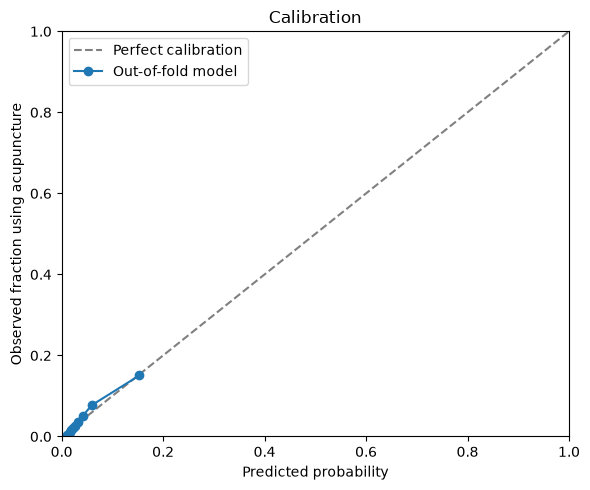

In [30]:
display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))
measured, predicted = calibration_curve(y, oof, n_bins=10, strategy="quantile")
calibration = pd.DataFrame({
    "mean_predicted_probability": predicted,
    "observed_fraction_users": measured,
})
display(calibration)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.plot(predicted, measured, "o-", label="Out-of-fold model")
ax.set(xlabel="Predicted probability", ylabel="Observed fraction using acupuncture",
       xlim=(0, 1), ylim=(0, 1), title="Calibration" + (" — synthetic demo" if USE_SYNTHETIC_DEMO else ""))
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "calibration.png", dpi=150)
plt.show()

## 8. Interpret patient probabilities and user counts

Sum probabilities rather than counting probabilities above 0.5. In the same cohort,
this sum checks whether the model reproduces observed utilization; it will often be
close to the observed user count. It does not reveal a maximum demand ceiling.

The probability sum among known current nonusers is a propensity summary, **not a
forecast of new users**. To forecast initiation, train on baseline nonusers with a
later new-use outcome and appropriate follow-up. No uncertainty interval or
improved-access intervention is estimated here.

In [31]:
predictions = wide[[ID, OUTCOME]].copy()
predictions["validation_fold"] = fold_number
predictions["probability_oof"] = oof
count_table = pd.DataFrame([
    {"quantity": "Observed current users", "value": int(y.sum())},
    {"quantity": "Sum of validated probabilities in this cohort", "value": float(oof.sum())},
    {"quantity": "Current nonusers", "value": int(y.eq(0).sum())},
    {"quantity": "Nonuser propensity sum — NOT a new-user forecast", "value": float(oof[y.eq(0)].sum())},
])
display(count_table)
display(predictions.drop(columns=ID).head())

,quantity,value
0,Observed current users,2.069680e+05
1,Sum of validated probabilities in this cohort,2.071006e+05
2,Current nonusers,5.024069e+06
3,Nonuser propensity sum — NOT a new-user forecast,1.873780e+05


,current_acupuncture_user,validation_fold,probability_oof
0,0,5,0.021359
1,0,2,0.065875
2,0,1,0.084237
3,0,3,0.012569
4,0,1,0.022362


## 9. Clinical groups, conditions and adjusted comparisons

The evidence-group summary shows each overlapping group's observed utilization
and average validated predicted use. A patient can appear in multiple rows:
**do not sum these group patient/user totals**. The 0/1/2/3+ table compares use
by condition burden within each group; these rows are descriptive, not adjusted
causal comparisons.

In **evidence-group mode**, evidence_group_odds_ratios.csv estimates adjusted odds
per additional distinct condition, accounting for demographics and counts in the
other groups. There is no reference evidence group. A larger OR describes
association with use and does not rank clinical benefit.

In **condition mode**, condition_odds_ratios_with_evidence.csv gives condition
effects with their evidence labels, preserving condition detail. These compare
presence with no record of the same condition, holding other predictors fixed.
With USE_COUNTS=True the presence coefficient additionally holds frequency
predictors fixed, so it should not be read as the total condition association.
Group-level ORs are marked not estimated in this mode; averaging individual
condition ORs would not estimate a group effect.

Age contrasts use <35; RUCC contrasts use 6. OR 1.5 means 50% higher odds, not
50 percentage points higher probability. No p-values or confidence intervals
are estimated, and clinical benefit cannot be inferred from utilization.

In [32]:
condition_summary = pd.DataFrame([
    {"condition": c,
     "patients_with_condition": int(wide[f"dx__{c}"].sum()),
     "users_with_condition": int(y[wide[f"dx__{c}"].eq(1)].sum())}
    for c in conditions
], columns=["condition", "patients_with_condition", "users_with_condition"])
coefficients = pd.DataFrame({
    "feature": model.named_steps["prepare"].get_feature_names_out(),
    "ridge_log_odds_coefficient": model.named_steps["logit"].coef_[0],
})
display(condition_summary)
display(coefficients.head(25))
comparison_table = make_comparison_table(model, wide, y)
age_comparisons = comparison_table.loc[comparison_table["comparison_group"].eq("Age")].copy()
rurality_comparisons = comparison_table.loc[comparison_table["comparison_group"].eq("RUCC")].copy()
age_observed = pd.DataFrame({"age_bucket": wide["age_bucket"], "observed": y, "predicted": oof})
age_calibration = age_observed.groupby("age_bucket", observed=True).agg(
    patients=("observed", "size"), observed_users=("observed", "sum"),
    observed_use_rate=("observed", "mean"), mean_predicted_probability=("predicted", "mean"),
).reindex(AGE_LABELS + ["Unknown"]).dropna(subset=["patients"]).reset_index()
print("Adjusted age odds ratios; reference:", AGE_REFERENCE)
display(age_comparisons)
print("Adjusted RUCC odds ratios; reference:", RURALITY_REFERENCE)
display(rurality_comparisons)
display(age_calibration)

condition_summary = condition_summary.merge(mapping_audit, on="condition", how="left", validate="one_to_one")
coef_lookup = dict(zip(coefficients["feature"], coefficients["ridge_log_odds_coefficient"]))
condition_effects = condition_summary.copy()
condition_effects["adjusted_odds_ratio"] = [
    float(np.exp(coef_lookup[f"diagnosis_presence__dx__{c}"]))
    if MODEL_MODE == "conditions" else np.nan for c in condition_effects["condition"]
]
condition_effects["comparison"] = "Recorded condition vs no record of the same condition"
condition_effects["status"] = (
    "Estimated, conditional on frequency" if USE_COUNTS else "Estimated"
) if MODEL_MODE == "conditions" else "Not estimated: evidence-group model"
group_summary, group_odds, group_by_count = evidence_results(
    model, wide, y, oof, conditions, evidence_mapping,
)
print("Evidence-group membership summaries (overlapping patients):")
display(group_summary)
if MODEL_MODE == "evidence_groups":
    print("Adjusted odds per additional distinct condition in each evidence group:")
    display(group_odds)
else:
    print("Individual condition odds ratios with evidence labels:")
    display(condition_effects)
display(group_by_count)

,condition,patients_with_condition,users_with_condition
0,Abdominal pain,141809,9666
1,Acute pancreatitis,8332,497
2,Adjustment and other stress-related disorders,316063,22359
3,Alcohol use disorder,146008,9379
4,Allergic rhinitis,194821,14166
...,...,...,...
93,Tinnitus,135340,9456
94,Tobacco use disorder,282779,15117
95,Tremor,53528,3306
96,Unspecified mood disorder,62607,4238


,feature,ridge_log_odds_coefficient
0,age_group__age_bucket_35-44,-0.317145
1,age_group__age_bucket_45-54,-0.202528
2,age_group__age_bucket_55-64,-0.219944
3,age_group__age_bucket_65-74,-0.317131
4,age_group__age_bucket_75+,-0.526815
5,age_group__age_bucket_<35,-0.458035
6,demographics__gender_Female,-0.777704
7,demographics__gender_Male,-1.263894
8,demographics__race_mod_AMERICAN INDIAN OR ALAS...,-0.229362
9,demographics__race_mod_ASIAN,0.151677


Adjusted age odds ratios; reference: <35


,comparison_group,category,reference,comparison_log_odds,adjusted_odds_ratio,odds_difference_percent,patients,observed_users,status
0,Age,<35,<35,0.000000,1.000000,0.000000,439293,16209,Reference
1,Age,35-44,<35,0.140889,1.151297,15.129721,709848,33622,Estimated
2,Age,45-54,<35,0.255507,1.291116,29.111551,707492,39276,Estimated
3,Age,55-64,<35,0.238091,1.268825,26.882476,948738,47587,Estimated
4,Age,65-74,<35,0.140904,1.151314,15.131396,990723,36614,Estimated
5,Age,75+,<35,-0.068780,0.933532,-6.646787,1434943,33660,Estimated
6,Age,Unknown,<35,NaN,NaN,NaN,0,0,Not estimated: category or reference absent


Adjusted RUCC odds ratios; reference: 6


...

Evidence-group membership summaries (overlapping patients):


,evidence_group,distinct_conditions_in_catalog,patients_with_any,observed_users_with_any,observed_use_rate_with_any,mean_oof_probability_with_any,sum_oof_probabilities_with_any,mean_distinct_conditions_with_any,interpretation
0,Group A - High/Strong,3,513161,47054,0.091694,0.090823,46606.610424,1.025084,Overlapping patient cohort; group totals canno...
1,Group A - Moderate,18,1646369,122450,0.074376,0.067881,111757.880686,1.324204,Overlapping patient cohort; group totals canno...
2,Group A - Low/Very Low,22,2937219,180081,0.061310,0.056396,165647.645139,1.625109,Overlapping patient cohort; group totals canno...
3,Group B,9,2154959,100237,0.046515,0.046080,99300.527892,1.244168,Overlapping patient cohort; group totals canno...
4,Group C,16,3093891,141476,0.045728,0.044538,137796.120521,1.480987,Overlapping patient cohort; group totals canno...
5,Group D,30,1824221,126685,0.069446,0.064610,117862.306491,1.463739,Overlapping patient cohort; group totals canno...
6,Unmapped,0,0,0,NaN,NaN,0.000000,NaN,Overlapping patient cohort; group totals canno...


Adjusted odds per additional distinct condition in each evidence group:


,evidence_group,feature,comparison,adjusted_log_odds_per_condition,adjusted_odds_ratio_per_condition,patients_with_any,status
0,Group A - High/Strong,egcount__1,One additional distinct recorded condition in ...,0.494809,1.640186,513161,Estimated
1,Group A - Moderate,egcount__2,One additional distinct recorded condition in ...,0.285096,1.329890,1646369,Estimated
2,Group A - Low/Very Low,egcount__3,One additional distinct recorded condition in ...,0.446654,1.563074,2937219,Estimated
3,Group B,egcount__4,One additional distinct recorded condition in ...,-0.075058,0.927690,2154959,Estimated
4,Group C,egcount__5,One additional distinct recorded condition in ...,0.034221,1.034813,3093891,Estimated
5,Group D,egcount__6,One additional distinct recorded condition in ...,0.138879,1.148985,1824221,Estimated
6,Unmapped,egcount__unmapped,One additional distinct recorded condition in ...,NaN,NaN,0,Not estimated: no variation or no modeled feature


,evidence_group,distinct_condition_count_band,patients,observed_users,observed_use_rate,mean_oof_probability,interpretation
0,Group A - High/Strong,0,4717876,159914,0.033895,0.034018,Descriptive/OOF comparison; not an adjusted gr...
1,Group A - High/Strong,1,500389,44620,0.089171,0.086805,Descriptive/OOF comparison; not an adjusted gr...
2,Group A - High/Strong,2,12672,2406,0.189867,0.246084,Descriptive/OOF comparison; not an adjusted gr...
3,Group A - High/Strong,3+,100,28,0.280000,0.520475,Descriptive/OOF comparison; not an adjusted gr...
4,Group A - Moderate,0,3584668,84518,0.023578,0.026597,Descriptive/OOF comparison; not an adjusted gr...
5,Group A - Moderate,1,1246963,73515,0.058955,0.048975,Descriptive/OOF comparison; not an adjusted gr...
6,Group A - Moderate,2,298579,32050,0.107342,0.098119,Descriptive/OOF comparison; not an adjusted gr...
7,Group A - Moderate,3+,100827,16885,0.167465,0.212162,Descriptive/OOF comparison; not an adjusted gr...
8,Group A - Low/Very Low,0,2293818,26887,0.011722,0.018072,Descriptive/OOF comparison; not an adjusted gr...
9,Group A - Low/Very Low,1,1739186,63276,0.036383,0.031734,Descriptive/OOF comparison; not an adjusted gr...


## 11. Save outputs

The output folder is separated by MODEL_MODE and diagnosis-frequency setting.

- condition_evidence_mapping.csv: condition-label audit, including Unmapped.
- condition_counts.csv: patient/user counts per condition with evidence labels.
- condition_odds_ratios_with_evidence.csv: condition effects in condition mode.
- evidence_group_odds_ratios.csv: per-additional-condition effects in group mode.
- evidence_group_summary.csv: overlapping group counts and observed/OOF use rates.
- evidence_group_by_count.csv: descriptive/OOF rates at burden 0, 1, 2 and 3+.
- age_bucket_odds_ratios.csv and rurality_odds_ratios.csv: requested contrasts.
- patient_probabilities.csv, summary.json, calibration.csv/png and model.joblib:
  predictions, validation, calibration and the fitted model plus feature/mapping metadata.

A model that does not estimate a particular kind of effect exports a missing OR
and an explicit status; no condition effect is manufactured from a group effect.
patients_wide.csv retains condition presence/frequency and group counts for
auditing; only the configured feature_columns enter the model.

In [33]:
summary = {
    "data_mode": "synthetic_demo" if USE_SYNTHETIC_DEMO else "input_data",
    "interpretation": "Current-utilization propensity; not a maximum or initiation forecast.",
    "validation": "Nested stratified cross-validation; conditional on the supplied condition list.",
    "use_counts": USE_COUNTS, "conditions": len(conditions),
    "model_mode": MODEL_MODE,
    "clinical_predictors": (
        "Counts of distinct recorded conditions per evidence group"
        if MODEL_MODE == "evidence_groups" else "Individual condition presence; optional frequency"
    ),
    "evidence_group_labels": EVIDENCE_GROUPS,
    "unmapped_conditions": unmapped_conditions,
    "mapped_conditions": len(conditions) - len(unmapped_conditions),
    "patients_with_unmapped_condition": int(wide[EVIDENCE_FEATURES[UNMAPPED_GROUP]].gt(0).sum()),
    "evidence_group_patients_overlap": True,
    "evidence_group_reference": None,
    "evidence_group_effect_unit": "One additional distinct condition within the same group",
    "feature_columns": feature_columns,
    "age_encoding": "categorical_buckets", "age_buckets": AGE_LABELS,
    "reporting_references": {"age_bucket": AGE_REFERENCE, "rurality": RURALITY_REFERENCE,
                             "gender": GENDER_REFERENCE, "race": RACE_REFERENCE},
    "missing_age": int(wide["age_bucket"].eq("Unknown").sum()),
    "missing_rurality": int(wide["rurality"].eq("Unknown").sum()),
    "out_of_fold_metrics": metrics,
    "current_nonusers": int(y.eq(0).sum()),
    "nonuser_propensity_sum_NOT_new_user_forecast": float(oof[y.eq(0)].sum()),
    "outer_fold_C": selected_penalties,
    "final_C": float(final.best_params_["logit__C"]),
    "limitations": [
        "If selected using these outcomes, the supplied condition catalog is not independently validated.",
        "Evidence labels are externally supplied metadata, not validated treatment benefit.",
        "Group-mode slopes assume a common log-odds effect per additional condition within each group.",
        "Group membership overlaps; group totals must not be added.",
        "Counts/conditions must precede the outcome and exclude acupuncture-generated records.",
        "Probability sums require representative sampling, comparable access and calibration.",
        "No maximum, initiation forecast, uncertainty interval, or causal expansion scenario is estimated.",
        "Clinical validity, decision impact, patient benefit and resource optimization: Data Insufficient.",
    ],
}
#wide.to_csv(OUTPUT_DIR / "patients_wide.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "patient_probabilities.csv", index=False)
calibration.to_csv(OUTPUT_DIR / "calibration.csv", index=False)
condition_summary.to_csv(OUTPUT_DIR / "condition_counts.csv", index=False)
coefficients.to_csv(OUTPUT_DIR / "model_coefficients.csv", index=False)
comparison_table.to_csv(OUTPUT_DIR / "adjusted_odds_ratios.csv", index=False)
age_comparisons.to_csv(OUTPUT_DIR / "age_bucket_odds_ratios.csv", index=False)
rurality_comparisons.to_csv(OUTPUT_DIR / "rurality_odds_ratios.csv", index=False)
age_calibration.to_csv(OUTPUT_DIR / "age_bucket_calibration.csv", index=False)
joblib.dump({
    "model": model, "conditions": conditions, "feature_columns": feature_columns,
    "use_counts": USE_COUNTS, "sklearn_version": sklearn.__version__,
    "model_mode": MODEL_MODE, "evidence_mapping": evidence_mapping,
    "evidence_features": EVIDENCE_FEATURES,
    "group_count_columns": evidence_columns(evidence_mapping),
    "age_buckets": AGE_LABELS, "age_reference": AGE_REFERENCE,
    "rurality_reference": RURALITY_REFERENCE,
}, OUTPUT_DIR / "model.joblib")
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved results to", OUTPUT_DIR.resolve())
mapping_audit.to_csv(OUTPUT_DIR / "condition_evidence_mapping.csv", index=False)
condition_effects.to_csv(OUTPUT_DIR / "condition_odds_ratios_with_evidence.csv", index=False)
group_odds.to_csv(OUTPUT_DIR / "evidence_group_odds_ratios.csv", index=False)
group_summary.to_csv(OUTPUT_DIR / "evidence_group_summary.csv", index=False)
group_by_count.to_csv(OUTPUT_DIR / "evidence_group_by_count.csv", index=False)

Saved results to C:\Users\VACOGRAUPE\OneDrive - Department of Veterans Affairs\Desktop\acupuncture_python_code\acupuncture_evidence_outputs\patient_analysis_evidence_groups


## Data that would improve the analysis

| Additional data | Necessity (1–5) | Likely source and accessibility |
|---|---:|---|
| Baseline/outcome dates, observation length and full population denominator | 5 | Health-system EHR/claims; nonpublic |
| Whether counts include acupuncture encounters | 5 | Claims service/date linkage; system/payer, nonpublic |
| Independent condition-selection period and original unfiltered conditions | 5 for validating the filter | Original claims/EHR extract; nonpublic |
| Facility, referral/access, wait time and travel distance | 4 for utilization; 5 for expansion | Operational/EHR records; primarily nonpublic |
| Eligibility, contraindications, willingness and service capacity | 5 for achievable demand | Clinical review, surveys and scheduling records; nonpublic |
| Condition severity/duration, comorbidity detail and social needs | 4 | EHR/clinical instruments; nonpublic |

Clinical validity, decision impact, patient-centered benefits and resource
optimization are **Data Insufficient** in this utilization-only model.

To compare the two clinical predictor modes, change MODEL_MODE. To compare
condition presence-only and frequency models, change `USE_COUNTS`, restart and rerun.
Selecting a preferred version from those validation results requires independent
confirmation or selection within the inner validation process.

References: [logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
[age categories](https://pandas.pydata.org/docs/reference/api/pandas.cut.html),
[one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html),
[calibration](https://scikit-learn.org/stable/modules/calibration.html),
[pandas pivot](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html),
[prediction-model development](https://www.bmj.com/content/386/bmj-2023-078276).

| Additional grouping data | Necessity (1–5) | Source and accessibility |
|---|---:|---|
| Condition-to-evidence-group lookup and its version/effective date | 5 for group interpretation | Your clinical evidence review or client classification; project-specific mapping is nonpublic unless published |
| Study population, indication, severity and benefit endpoints behind each label | 4 | Underlying clinical evidence reviews; accessibility varies by source; no specific source supplied here |

The supplied evidence group alone does not establish clinical validity, decision
impact, patient-centered benefit or resource optimization: **Data Insufficient**.
References also include
[interpreting regression coefficients](https://scikit-learn.org/stable/auto_examples/inspection/plot_linear_model_coefficient_interpretation.html).
